*  DSC540-T303 Data Preparation (2265-1)
*  Weeks 5 & 6 Exercises
*  David Jorgensen

# Weeks 5 & 6 Exercises

# Instructions

1. The Data Wrangling Workshop: Activity 5.01, page 281
2. The Data Wrangling Workshop: Activity 6.01, page 309
3. Insert data into a SQL Lite database – create a table with the following data below that you will create yourself (Hint on how to create the SQL: Python for Data Analysis 2nd edition page 191, Python for Data Analysis 3rd Edition: Page 199):
     - Name, Address, City, State, Zip, Phone Number
     - Add at least 10 rows of data and submit your code with a query generating your results.

# Assignment

## 5.01

In this activity, you have been given a Wikipedia page where you have the GDP of all countries
listed. You have to create three DataFrames from the three sources mentioned on the page
(https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)).

In [19]:
# Load Libraries
import urllib.request
from urllib.parse import urlparse
from bs4 import BeautifulSoup
import pandas as pd

In [20]:
# Scrape table from Wikipedia page
url = 'https://en.wikipedia.org/wiki/List_of_countries_by_GDP_(nominal)'

# Get HTML content
response = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(response, timeout=30) as response:
    html_content = response.read().decode('utf-8', errors='ignore')

# Create DataFrames
soup = BeautifulSoup(html_content)

In [21]:
# Get table data
data_table = soup.find("table", {"class": "wikitable"})
all_rows = data_table.tbody.findAll('tr')

In [22]:
# Row 0 uses <th> for headers; remaining rows use <td> for data
headers = [th.getText().strip() for th in all_rows[0].findAll('th')]
data_rows = [
    [td.getText().strip() for td in row.findAll('td')]
    for row in all_rows[1:]
    if len(row.findAll('td')) == len(headers)
]

df_full = pd.DataFrame(data_rows, columns=headers)

# Clean DataFrames
country_col = headers[0]
source_names = headers[1:]
print(f"Sources: {source_names}")

Sources: ['IMF(2026)[1]', 'World Bank(2024)[6]', 'United Nations(2024)[7]']


In [23]:
# Create new DataFrames, one for each source
df1 = df_full[[country_col, source_names[0]]].copy()
df2 = df_full[[country_col, source_names[1]]].copy()
df3 = df_full[[country_col, source_names[2]]].copy()

In [24]:
df1.head()

,Country/Territory,IMF(2026)[1]
0,World,"126,295,331"
1,United States,"32,383,920"
2,China[n 1],"20,851,593"
3,Germany,"5,452,858"
4,Japan,"4,379,253"


In [25]:
df2.head()

,Country/Territory,World Bank(2024)[6]
0,World,"111,326,370"
1,United States,"28,750,956"
2,China[n 1],"18,743,803"
3,Germany,"4,685,593"
4,Japan,"4,027,598"


In [26]:
df3.head()

,Country/Territory,United Nations(2024)[7]
0,World,"100,834,796"
1,United States,"29,298,000"
2,China[n 1],"18,743,802"
3,Germany,"4,659,929"
4,Japan,"4,026,211"


## 6.01

In this activity, we will identify and get rid of outliers. Here, we have a CSV file. The goal here is
to clean the data by using the knowledge that we have learned about so far and come up with a
nicely formatted DataFrame. Identify the type of outliers and their effect on the data and clean
the messy data. 

The dataset that we have used here can be found in the visit_data.csv file. This file contains
data generated by a random data generator, and it contains people's names, their gender,
email_id, ip_address, and the number of visits they made to a particular web page. 

The dataset can be found at https://packt.live/2YajrLJ. 

The steps that will help you solve this activity are as follows: 

1. Read the visit_data.csv file. 
2. Check for duplicates. 
3. Check whether any essential column contains NaN. 
4. Get rid of the outliers. 
5. Report the size difference. 
6. Create a box plot to check for outliers. 
7. Get rid of any outliers.

The final output should look like this: 
After getting rid of outliers the new size of the data is – 923.

In [47]:
# Load libraries
import matplotlib.pyplot as plt


In [30]:
# Read visit_data.csv
visit_df = pd.read_csv('visit_data.csv')
visit_df.head()

,id,first_name,last_name,email,gender,ip_address,visit
0,1,Sonny,Dahl,sdahl0@mysql.com,Male,135.36.96.183,1225.0
1,2,NaN,NaN,dhoovart1@hud.gov,NaN,237.165.194.143,919.0
2,3,Gar,Armal,garmal2@technorati.com,NaN,166.43.137.224,271.0
3,4,Chiarra,Nulty,cnulty3@newyorker.com,NaN,139.98.137.108,1002.0
4,5,NaN,NaN,sleaver4@elegantthemes.com,NaN,46.117.117.27,2434.0


In [33]:
# Check for duplicate emails
visit_df.duplicated(subset='email').sum()

np.int64(0)

In [34]:
# Check for duplicate ip_address
visit_df.duplicated(subset='ip_address').sum()

np.int64(0)

Email is an important column here as it's unique to each visitor. Unless this is a workplace user log, ip address can also serve as a unique identifier.

In [36]:
# Check whether any essential column contains NaN
essential_columns = ['email', 'ip_address', 'visit']
visit_df[essential_columns].isna().sum()

email          0
ip_address     0
visit         26
dtype: int64

We need visit data for later reports, so visit values of NaN are not useful.

In [41]:
# Get rid of the rows with NaN visit values and report DataFrame size difference
print(f'Old list size: {visit_df.shape[0]}')
visit_df = visit_df.dropna(subset=['visit'])
print(f'New list size after dropping null visit rows: {visit_df.shape[0]}')


Old list size: 974
New list size after dropping null visit rows: 974


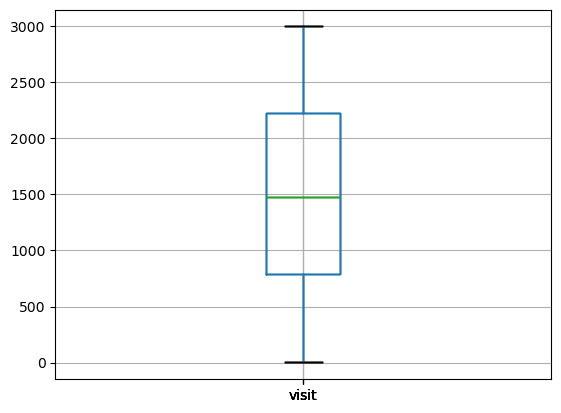

In [48]:
# Create boxplot to check for outliers
visit_df.boxplot(column='visit')
plt.show()

In [49]:
# Get rid of values beyond 2900 and below 100
visit_df = visit_df[(visit_df['visit'] >= 100) & (visit_df['visit'] <= 2900)]

# Report new size of DataFrame after removing outliers
visit_df.shape[0]

923

## SQL Write

Insert data into a SQL Lite database – create a table with the following data below that you will create yourself (Hint on how to create the SQL: Python for Data Analysis 2nd edition page 191, Python for Data Analysis 3rd Edition: Page 199):

1. Name, Address, City, State, Zip, Phone Number
2. Add at least 10 rows of data and submit your code with a query generating your results.

In [53]:
# Load Libraries
import sqlite3

In [51]:
# Create DataFrame containing 10 rows of name, address, city, state, zip, and phone_number
ledger_df = pd.DataFrame({
    'Name': ['John Doe', 'Jane Smith', 'Alice Johnson', 'Bob Brown', 'Charlie Davis', 'David Wilson', 'Eve Taylor', 'Frank White', 'Grace Green', 'Hank Black'],
    'Address': ['123 Main St', '456 Elm St', '789 Oak St', '101 Pine St', '202 Maple St', '303 Birch St', '404 Cedar St', '505 Walnut St', '606 Cherry St', '707 Dogwood St'],
    'City': ['Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield', 'Springfield'],
    'State': ['IL', 'IL', 'IL', 'IL', 'IL', 'IL', 'IL', 'IL', 'IL', 'IL'],
    'Zip': [62704, 62705, 62706, 62707, 62708, 62709, 62710, 62711, 62712, 62713],
    'Phone': ['555-1234', '555-5678', '555-9012', '555-3456', '555-7890', '555-2345', '555-6789', '555-0123', '555-4567', '555-8901']
})
ledger_df

,Name,Address,City,State,Zip,Phone
0,John Doe,123 Main St,Springfield,IL,62704,555-1234
1,Jane Smith,456 Elm St,Springfield,IL,62705,555-5678
2,Alice Johnson,789 Oak St,Springfield,IL,62706,555-9012
3,Bob Brown,101 Pine St,Springfield,IL,62707,555-3456
4,Charlie Davis,202 Maple St,Springfield,IL,62708,555-7890
5,David Wilson,303 Birch St,Springfield,IL,62709,555-2345
6,Eve Taylor,404 Cedar St,Springfield,IL,62710,555-6789
7,Frank White,505 Walnut St,Springfield,IL,62711,555-0123
8,Grace Green,606 Cherry St,Springfield,IL,62712,555-4567
9,Hank Black,707 Dogwood St,Springfield,IL,62713,555-8901


In [ ]:
# Upload ledger_df into local SQLite database
con = sqlite3.connect("mydata.sqlite")
ledger_df.to_sql('ledger', con, if_exists='replace', index=False)
con.close()

In [55]:
# Print ledger table from SQLite
con = sqlite3.connect("mydata.sqlite")
cursor = con.execute("SELECT * FROM ledger")
rows = cursor.fetchall()
for row in rows:
    print(row)
con.close()

('John Doe', '123 Main St', 'Springfield', 'IL', 62704, '555-1234')
('Jane Smith', '456 Elm St', 'Springfield', 'IL', 62705, '555-5678')
('Alice Johnson', '789 Oak St', 'Springfield', 'IL', 62706, '555-9012')
('Bob Brown', '101 Pine St', 'Springfield', 'IL', 62707, '555-3456')
('Charlie Davis', '202 Maple St', 'Springfield', 'IL', 62708, '555-7890')
('David Wilson', '303 Birch St', 'Springfield', 'IL', 62709, '555-2345')
('Eve Taylor', '404 Cedar St', 'Springfield', 'IL', 62710, '555-6789')
('Frank White', '505 Walnut St', 'Springfield', 'IL', 62711, '555-0123')
('Grace Green', '606 Cherry St', 'Springfield', 'IL', 62712, '555-4567')
('Hank Black', '707 Dogwood St', 'Springfield', 'IL', 62713, '555-8901')
